C:\Users\thoma\AppData\Local\Temp\ipykernel_18780\1656830471.py:23: RuntimeWarning: divide by zero encountered in log
  plt.plot(ns, np.log(d), label=f"theta = {t}")


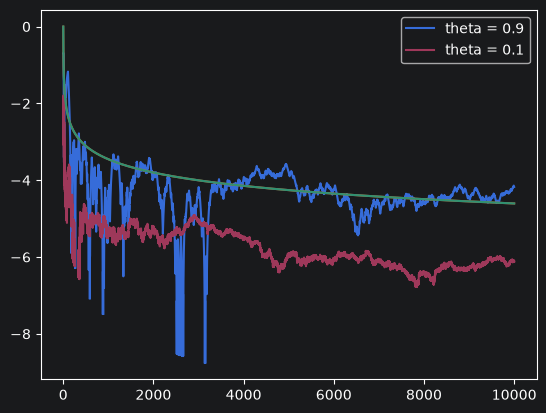

In [1]:
import numpy as np
import matplotlib.pyplot as plt
# 5
from week11 import *
pi = [1/4, 1/2, 1/4]
N = 10000
ts = [0.9, 0.1]
ns = np.arange(1, N+1)

for t in ts:
    p_mat = np.array([[t, 1-t, 0],
                  [(1-t) / 2, t, (1-t)/2],
                  [0, 1-t, t]])
    current_state = np.random.randint(1,4)

    X = np.empty(N, dtype=int)
    d = np.empty(N, dtype=float)
    for i in range(N):
        X[i] = markov_sample(current_state, p_mat)
        current_state = X[i]

        d[i] = np.abs(np.mean(X[:i+1] == 2) - pi[1])
    plt.plot(ns, np.log(d), label=f"theta = {t}")
    plt.plot(ns, -np.log(np.sqrt(np.arange(1,N+1))))
plt.legend()
plt.show()



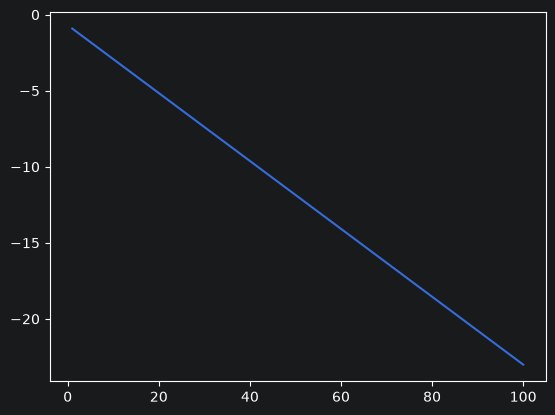

Slope: -0.22314355689543178
Geometric rate: 0.7999999955350224


EigResult(eigenvalues=array([-0.8+0.j,  0.1+0.j,  1. +0.j]), eigenvectors=array([[ 5.77350269e-01+0.j,  7.07106781e-01+0.j,  5.77350269e-01+0.j],
       [-5.77350269e-01+0.j,  1.08873246e-16+0.j,  5.77350269e-01+0.j],
       [ 5.77350269e-01+0.j, -7.07106781e-01+0.j,  5.77350269e-01+0.j]]))

In [2]:
# 6
t = 0.1
p_mat = np.array([[t, 1-t, 0],
                  [(1-t) / 2, t, (1-t)/2],
                  [0, 1-t, t]])
P12 = np.array([np.linalg.matrix_power(p_mat, n)[0,1] for n in range(1,101)])

log_diff = np.log(np.abs(P12 - pi[1]))
ns = np.arange(1, 100+1)
plt.plot(ns, log_diff)
plt.show()

d = np.abs(P12 - pi[1])

slope, intercept = np.polyfit(ns, np.log(d), 1)

rho = np.exp(slope)

print("Slope:", slope)
print("Geometric rate:", rho)

np.linalg.eig(p_mat)